In [2]:
import pandas as pd
import glob
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
from scipy.fft import fft, ifft, fftfreq
import matplotlib.pyplot as plt

# 1. read in the lightcurves for a chip and run

In [2]:
lcvsdf = pd.DataFrame(data=[l.replace(".csv","").split("_") for l in glob.glob("../../pcastuff/lightcurves/*000686_zg_c07_x_*")])
lcvsdf

,0,1,2,3,4,5,6,7,8,9,10
0,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,2,2706,0836
1,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0014,4,0203,1578
2,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0010,3,2417,0476
3,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,4,1402,0297
4,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1646,2313
...,...,...,...,...,...,...,...,...,...,...,...
6565,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1210,2731
6566,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0007,3,0162,1985
6567,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0000,1,0373,2299
6568,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0019,3,2230,0151


In [3]:
#how many lcvs per star?
inds = lcvsdf.groupby([8,9,10]).count()   
inds

0   1   2   3   4   5   6   7
8 9    10                                  
1 0206 1805  30  30  30  30  30  30  30  30
  0304 1835  30  30  30  30  30  30  30  30
  0373 2299  30  30  30  30  30  30  30  30
  0570 0100  30  30  30  30  30  30  30  30
  0617 1782  30  30  30  30  30  30  30  30
...          ..  ..  ..  ..  ..  ..  ..  ..
4 2981 0154  30  30  30  30  30  30  30  30
  3001 1114  30  30  30  30  30  30  30  30
  3010 2091  30  30  30  30  30  30  30  30
  3024 2016  30  30  30  30  30  30  30  30
  3061 1283  30  30  30  30  30  30  30  30

[219 rows x 8 columns]

# 2. shift and concatenate every sequence for this run for every star

In [4]:
#concatenate lcvs
df = []

for iis in inds.index: #star
    lcv = []
    #print(iis)
    for i in range(1,29):
        l = f"../../pcastuff/lightcurves/lightcurve_ztf_20221020148032_000686_zg_c07_x_%04d_{iis[0]}_{iis[1]}_{iis[2]}.csv"%i #sequence
        #print(l)
        lcv.append(pd.read_csv(l)["flux_hap_2"])
        #print(len(pd.concat(lcv)))
        
    df.append(pd.concat(lcv)[int(iis[2]):83160+int(iis[2])])

df = pd.DataFrame(data=np.array(df).T)
df.shape


(83160, 219)

In [5]:
df.head() #each column is an lcv

,0,1,2,3,4,5,6,7,8,9,...,209,210,211,212,213,214,215,216,217,218
0,58.609619,341.462219,206.361374,198.677109,86.402710,64.395432,567.241455,296.968689,101.680740,956.168030,...,211.657471,74.915680,758.367432,164.161545,569.227295,84.902115,269.869873,92.961319,385.227844,642.027222
1,57.128128,331.357910,198.467346,187.562500,97.725800,45.729614,568.145264,257.697571,113.813812,930.559998,...,188.355530,71.030441,764.262573,159.496460,576.451599,66.293442,276.909393,106.761902,448.742737,642.823303
2,49.294189,341.624512,211.107101,210.579529,111.730423,44.142776,577.357788,270.220825,117.164490,960.337708,...,205.553955,77.832428,755.829834,168.712723,555.590637,61.043396,270.610840,131.952911,365.233398,645.124268
3,39.039398,349.423889,203.625443,197.479477,110.331711,40.030441,571.917053,275.473083,117.847992,943.648193,...,202.484268,68.264938,735.179016,153.530365,556.234436,103.906494,280.946930,96.611191,424.560669,652.142822
4,50.917496,360.234344,184.528473,200.797867,110.018692,53.243546,563.759888,273.255493,120.705414,923.460327,...,204.957855,71.785248,790.510376,147.368713,574.263489,111.253662,281.847504,101.216461,406.495087,645.422363


In [61]:
#shar's version
pred = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_reupdated.csv', names=['filename', 'binary', 'rf'])
good = pred[pred['binary']==0]['filename']

lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
# lightcurve_path_filtered = '/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'
# lc_filenames = np.load('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_good.npy')

#goal...
#make a function that takes the filename of the begining one
#loads it
#loads the rest of them
#concatenates it
#subtracts the beginning and end to make it a standard size
def make_big_array(filename, total_len = 3080*27):
    # filename_list = []
    lcs_total = []
    
    for i in range(1, 29):
        new_filename = filename[:48]+f'{int(i):02}'+filename[50:]
        # filename_list.append(new_filename)
        lc = pd.read_csv(lightcurve_path+new_filename)['flux_hap_2']
        lcs_total = np.hstack((lcs_total,lc))
    closest_y = int(filename[-8:-4])
    lcs_adjust = lcs_total[closest_y:total_len+closest_y]
    return  lcs_adjust
     
    
        

# all_lcs = [] 
# for filename in good[:200].values:
#     try:
#         lcs_adjust = make_big_array(filename)
#         all_lcs.append(lcs_adjust)
#     except:
#         continue

In [59]:
3080*27

83160

In [97]:
good = np.array(good)

In [101]:
all_files = good

In [110]:
all_files[1][-20:-16]

'0017'

In [99]:
our_files = []

for file in all_files:
    if file[-20:-16]=='0000':
        our_files.append(file)

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [26]:
import os

In [31]:
list_chip_02 = []
direc = "/lustre/lrspec/ZTF_data/lightcurves/1020/"
fnames = [file for file in os.listdir(direc) if file.startswith("lightcurve_ztf_20221020148032_000686_zg_c02_x_0002")]
    

In [65]:

direc = "/lustre/lrspec/ZTF_data/lightcurves/1020/"
fnames7 = [file for file in os.listdir(direc) if file.startswith("lightcurve_ztf_20221020148032_000686_zg_c07_x_0002")]
    

In [67]:
all_lcs_c07_shortened = [] 
for filename in fnames7:
    try:
        lcs_adjust = make_big_array(filename)
        all_lcs_c07_shortened.append(lcs_adjust)
    except:
        continue

In [62]:
all_lcs_c02_shortened = [] 
for filename in fnames:
    try:
        lcs_adjust = make_big_array(filename)
        all_lcs_c02_shortened.append(lcs_adjust)
    except:
        continue

In [68]:
all_lcs_c07_shortened = np.array(all_lcs_c07_shortened)

In [37]:
all_lcs_c02 = np.array(all_lcs_c02)

In [157]:
lc = np.load('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/lightcurve_ztf_20221020154120_000640_zi_c10_x_0000_2_2580_0530_time_adjusted_concat.npy')

In [159]:
lc.shape

(86240,)

## assess common components

In [12]:
np.shape(all_lcs)

(182, 86240)

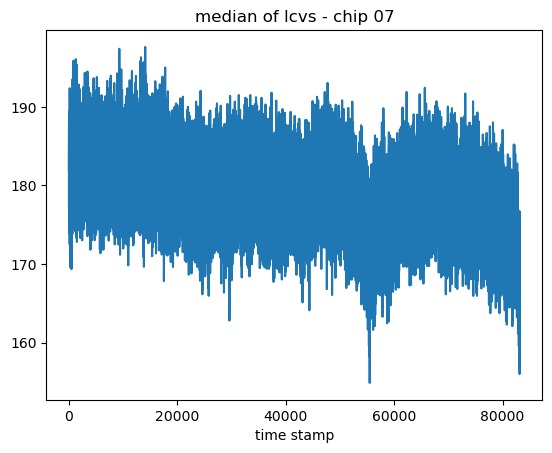

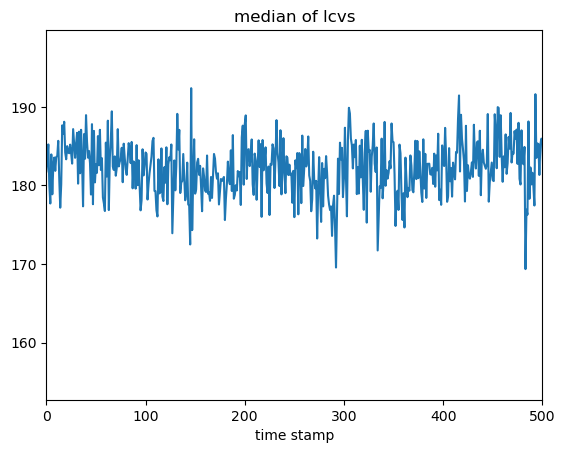

In [69]:
data_matrix = all_lcs_c07_shortened
plt.plot(np.median(data_matrix, axis=0))
plt.title("median of lcvs - chip 07")
plt.xlabel("time stamp")
plt.show()

plt.plot(np.median(data_matrix, axis=0))
plt.xlim(0,500)
plt.title("median of lcvs")
plt.xlabel("time stamp");

NOTE: the low frequency components look coherent, the high frequency components look stochastic

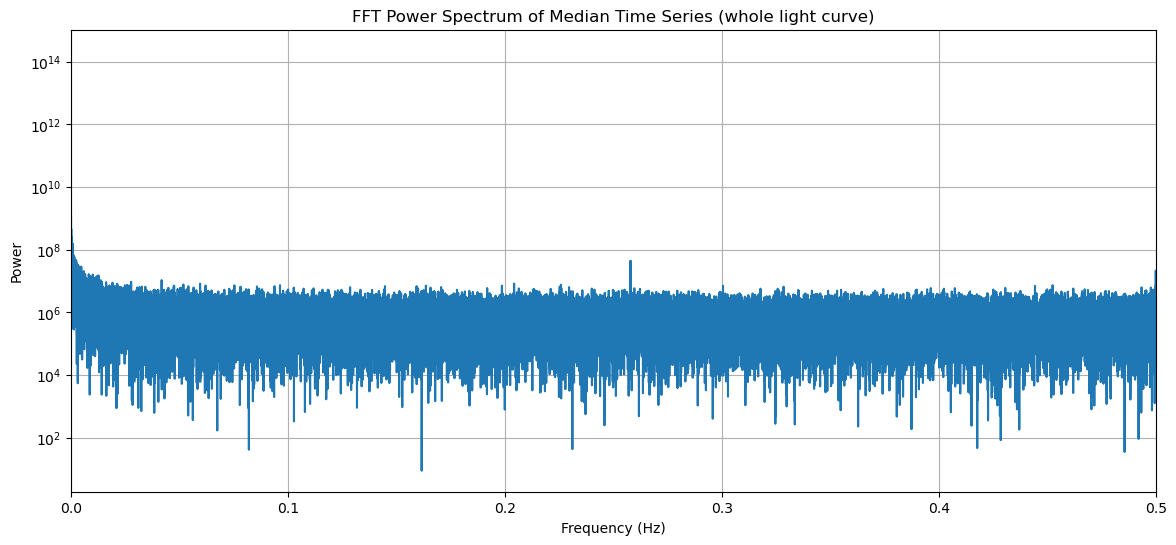

In [70]:
#median FFT

n = data_matrix.shape[1]
fft_vals = fft(np.median(data_matrix, axis=0))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series (whole light curve)')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

there is one high frequency at 0.25Hz (1/timestamp) but ignore for now

# 3. low pass filter in fourier space

test different frequencies: what is the frequency at which lcvs become significantly less correlated?

In [44]:
def apply_fft_lowpass(data, fs=1, fc=0.003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))


In [57]:
data_matrix.T.shape

(86240, 219)

In [73]:
fc =  0.0003
df_lowpass = pd.DataFrame(
        [apply_fft_lowpass(data_matrix.T[:, i], 1, fc) for i in range(data_matrix.T.shape[1])]
    )
df_highpass = all_lcs_c07_shortened - df_lowpass


In [1]:
df_highpass

NameError: name 'df_highpass' is not defined

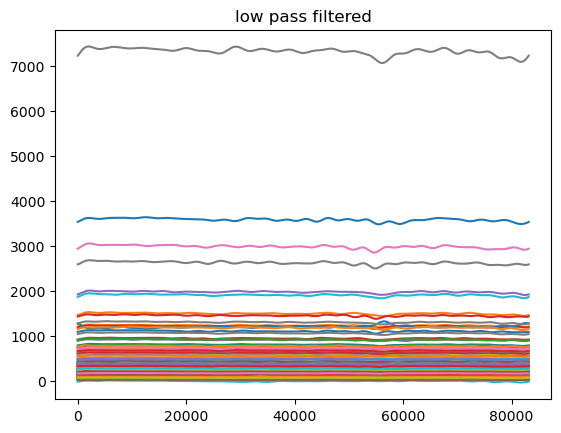

In [75]:
df_lowpass.T.plot(legend=None)
plt.title("low pass filtered");

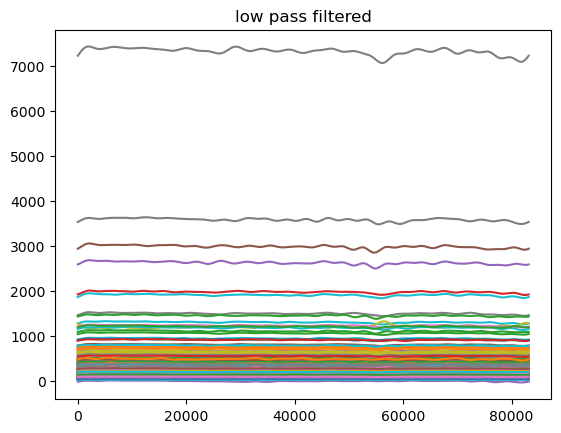

In [223]:
df_lowpass.plot(legend=None)
plt.title("low pass filtered");

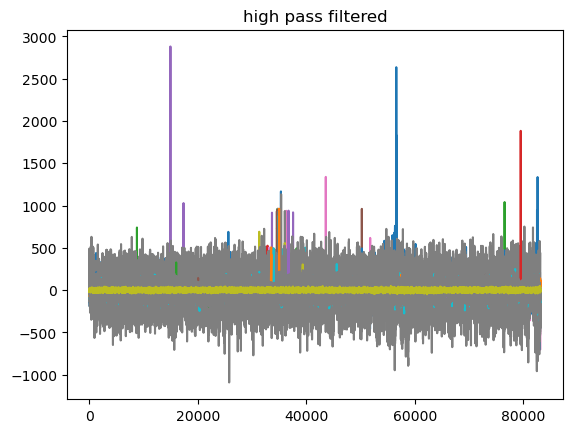

In [76]:
df_highpass.T.plot(legend=None)
plt.title("high pass filtered");

## scaling - just recenter the lightcurves before PCA (we scale to visualize but do not use scaled lcvs)

In [82]:
X = df_lowpass.values.T
X_centered = X - np.mean(X, axis=0)
Xdo = X_centered

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_centered)
#IF YOU WANT TO SCALE
#Xdo = X_scaled

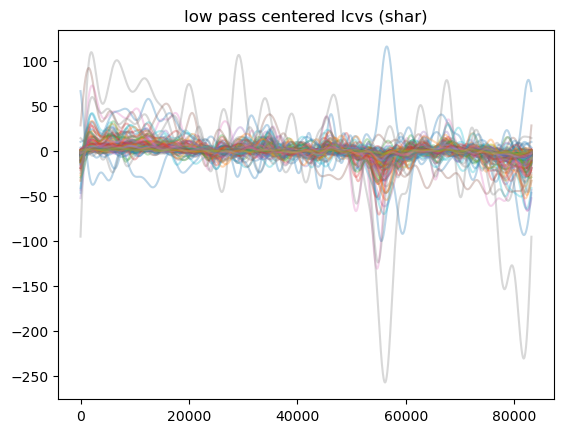

In [111]:
plt.plot(X_centered, alpha=0.3);
plt.title("low pass centered lcvs (shar)");

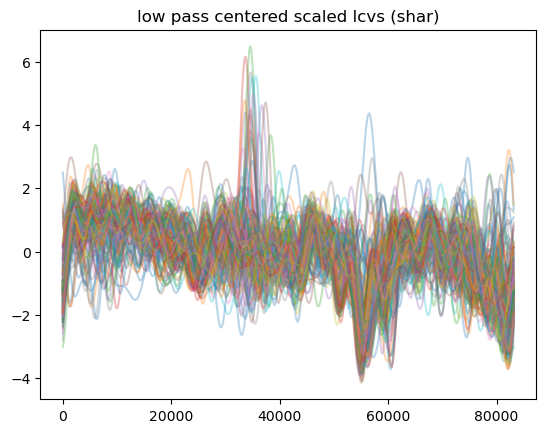

In [91]:
plt.plot(X_scaled, alpha=0.3);
plt.title("low pass centered scaled lcvs (shar)");

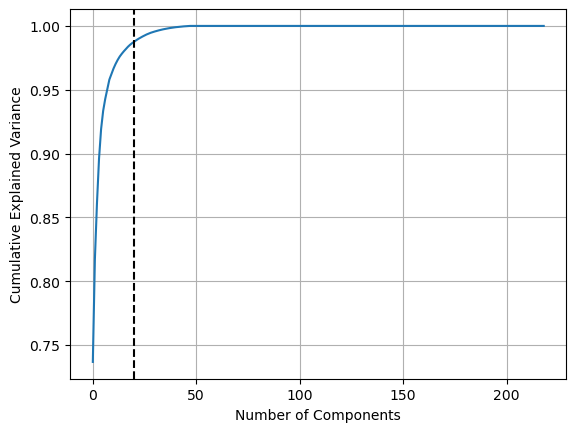

In [85]:
pca = PCA()
pca.fit(Xdo)

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.axvline(20, c="k", ls="--")
plt.grid(True)
plt.show()


with 10 components we are already above 95% variance. Use 20

# 4. run PCA decomposition

In [112]:
Xdo.shape

(83160, 219)

In [129]:
Xdo.argmax(axis=0)

array([12038, 11964,  5423,  2241, 67213,  2439, 36251,  8064,  8021,
       33682, 74706,  5595, 28755,  8471, 14934,  1963,  2125, 49454,
       12011,  8114,  2402, 12094, 38347, 17714, 34787,  4963,  1969,
       10021,  5181,  5504, 29197,  4919,  2216,  2088, 37687, 37399,
        2492, 11258,  6669, 12473, 28934,  2101, 78729, 33668, 33695,
        2060,  8164,  7812, 29402,  1930, 12499,  2691,  2038,  5346,
        5751,  1987,  9712,  7791,  2120,  5965,  8673,  1950, 34690,
        5949,  2528,  5051, 11992, 10179,  2126,  2025, 67382, 12371,
       34582, 34633, 29198,  2970, 12153, 36139,  5911,  4971, 12449,
        4644,  5904,  3353,  2213,  6247,  8531, 12579, 29842, 35597,
        5406,  2226,  6054,  2489, 12674, 26431, 30703, 57051,  8784,
        2013,  5412,  8222,  5556, 19344,  1736, 34527,  5868,  5256,
        8773,  4594,  7693,  2095,  9619,  2136,  2049,  9429,  2135,
        2007, 13169, 39889,  8683,  2026, 10515,  8501,  5997,  2549,
        2189,  8801,

In [139]:
import sklearn

In [140]:
sklearn.__version__

'1.2.2'

In [133]:
np.save('/lustre/lrspec/ZTF_data/Xdo.npy',Xdo)

In [143]:
np.isclose?

Signature:       np.isclose(a, b, rtol=1e-05, atol=1e-08, equal_nan=False)
Call signature:  np.isclose(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function isclose at 0x2aae8e6c62a0>
File:            /lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/numeric.py
Docstring:      
Returns a boolean array where two arrays are element-wise equal within a
tolerance.

The tolerance values are positive, typically very small numbers.  The
relative difference (`rtol` * abs(`b`)) and the absolute difference
`atol` are added together to compare against the absolute difference
between `a` and `b`.

.. warning:: The default `atol` is not appropriate for comparing numbers
             that are much smaller than one (see Notes).

Parameters
----------
a, b : array_like
    Input arrays to compare.
rtol : float
    The relative tolerance parameter (see Notes).
atol : float
    The absolute tolerance parameter (see Notes).
equal_nan : 

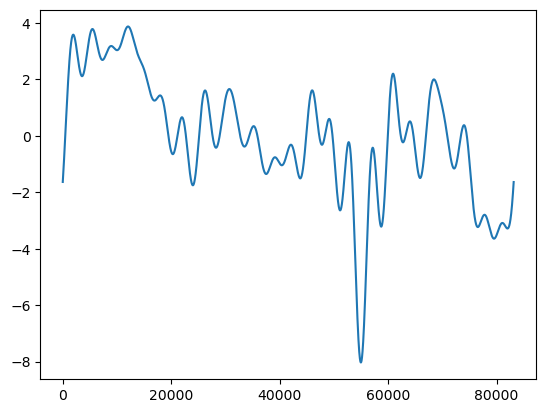

In [132]:
plt.plot(Xdo[:,0])

Text(0.5, 1.0, 'common noise (shar)')

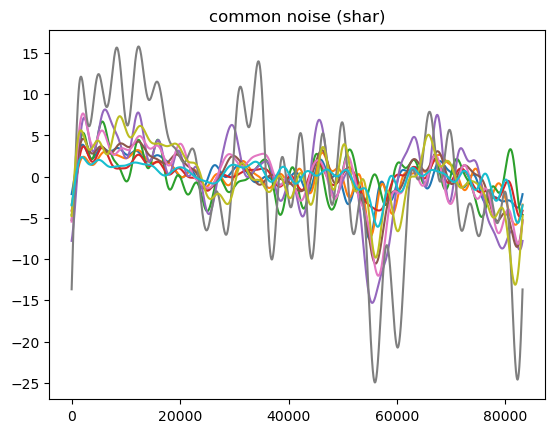

In [141]:
k = 10
pca_noise = PCA(n_components=k)
pca_noise.fit(Xdo)
# the common noise is the 20-components reconstructions of the lowpass data
common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))
for i in range(k):
    plt.plot(common_noise[:,i]);
plt.title("common noise (shar)")

Text(0.5, 1.0, 'common noise (shar)')

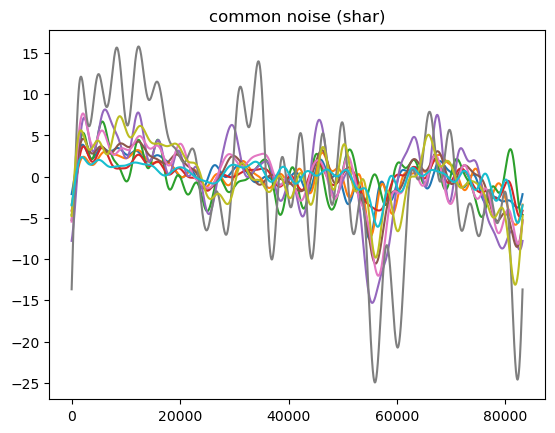

In [89]:
k = 10
pca_noise = PCA(n_components=k)
pca_noise.fit(Xdo)
# the common noise is the 20-components reconstructions of the lowpass data
common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))
for i in range(k):
    plt.plot(common_noise[:,i]);
plt.title("common noise (shar)")

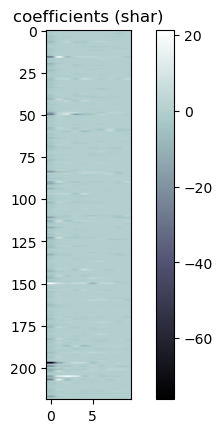

In [152]:
loadings = pca_noise.components_.T * np.sqrt(pca_noise.explained_variance_)
plt.imshow(loadings, aspect=0.2, cmap='bone')
plt.colorbar()

plt.title("coefficients (shar)");

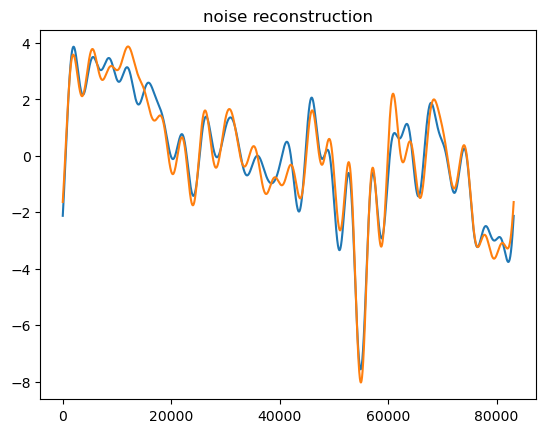

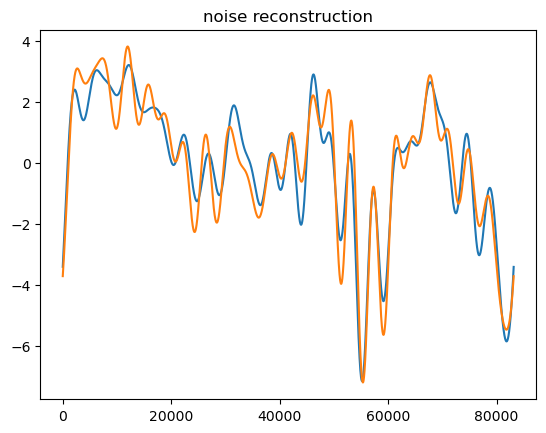

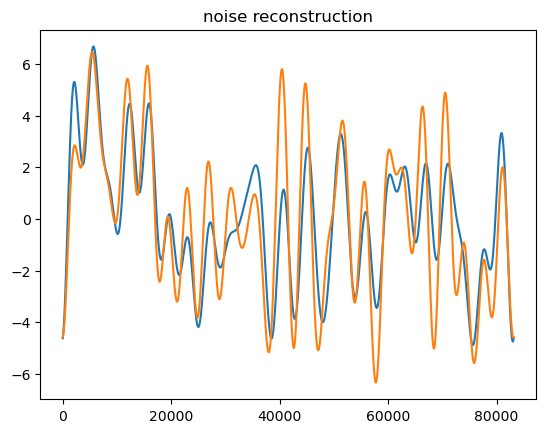

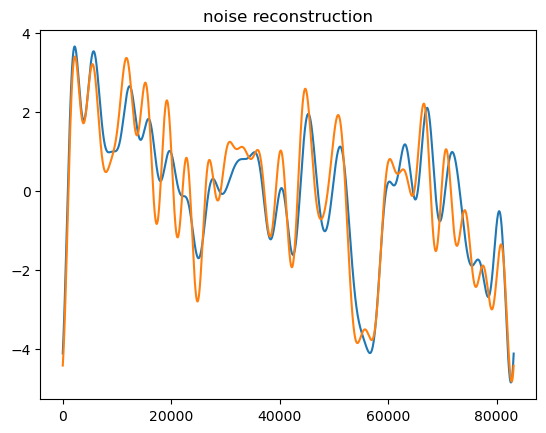

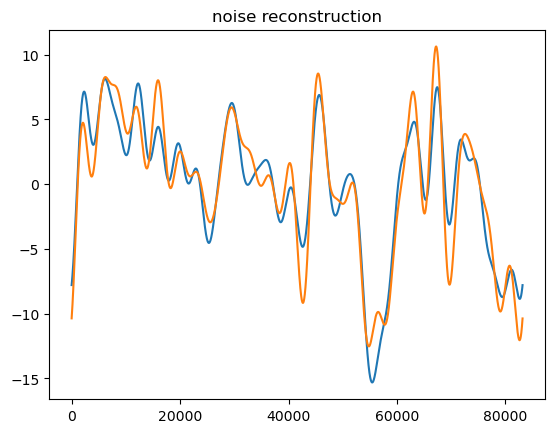

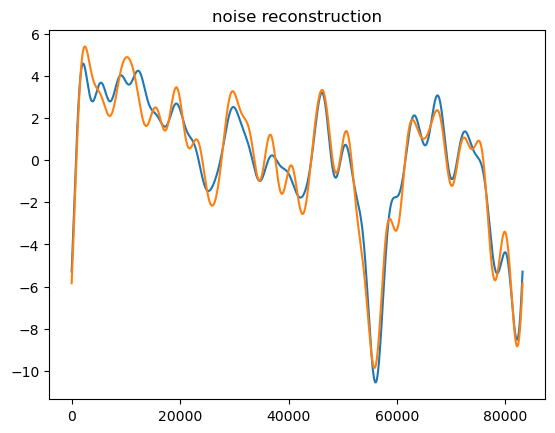

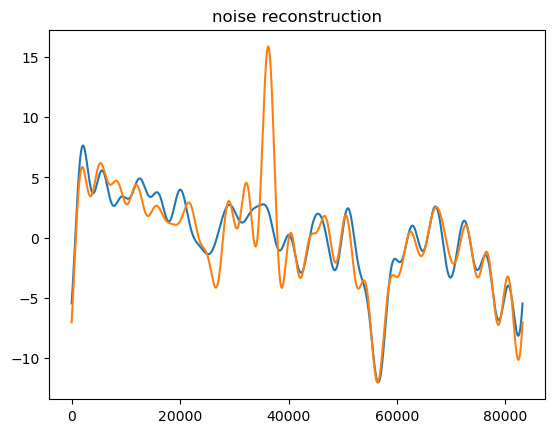

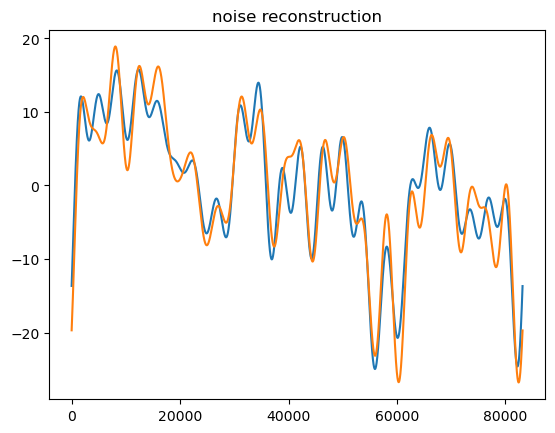

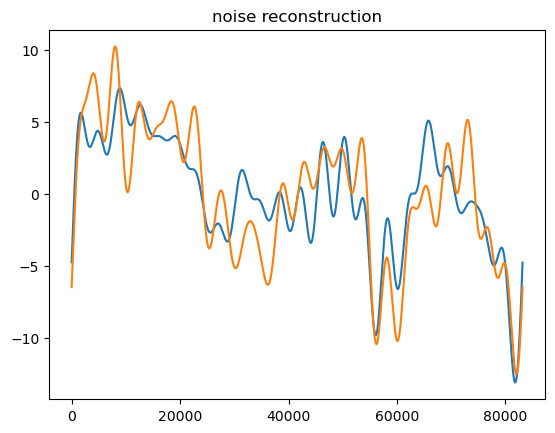

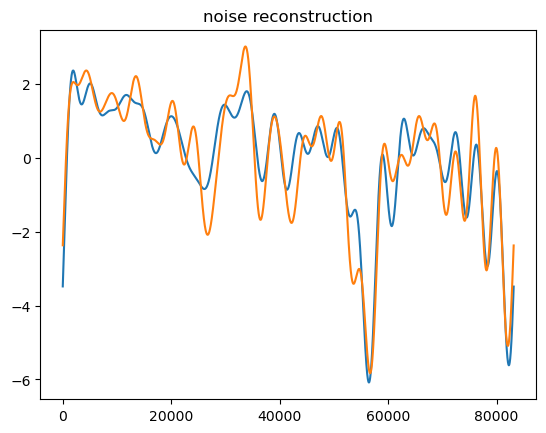

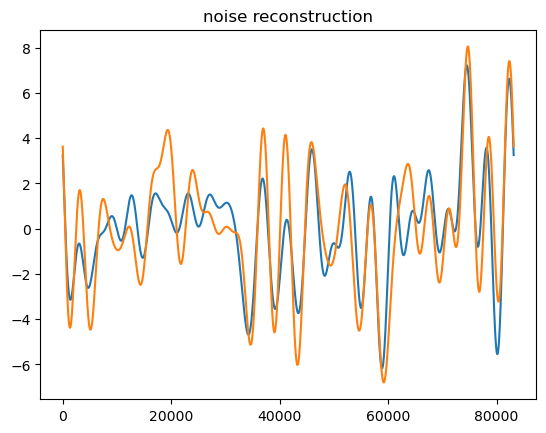

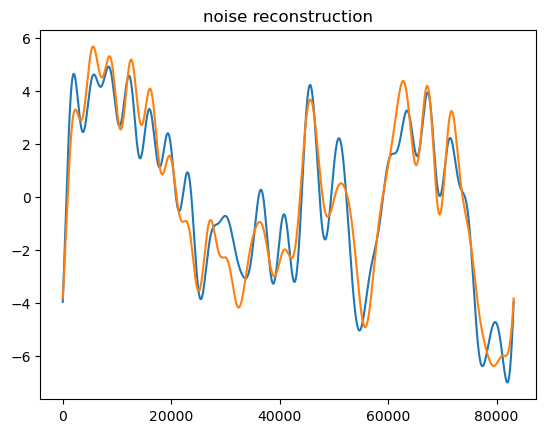

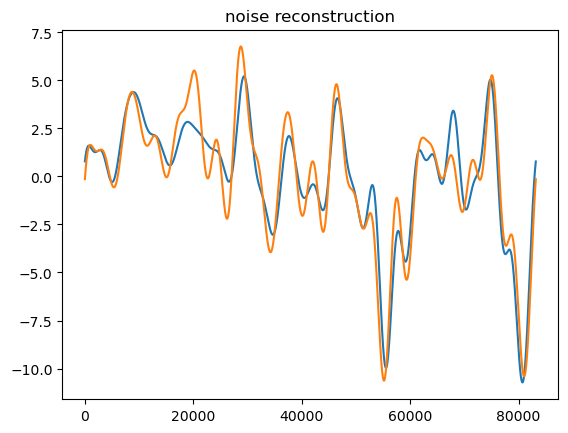

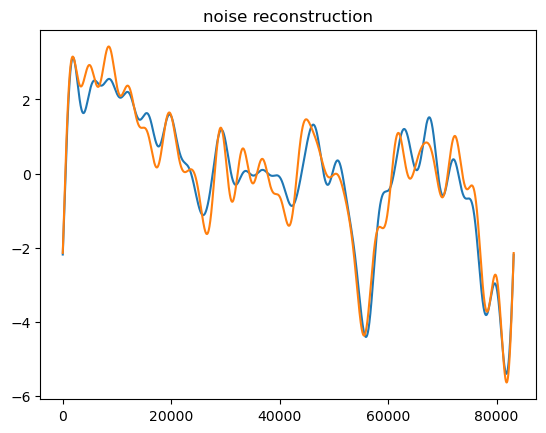

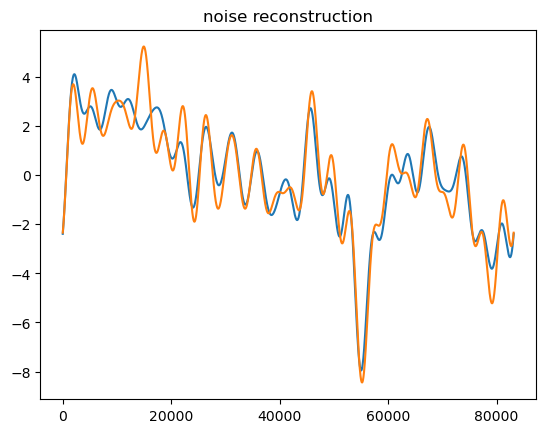

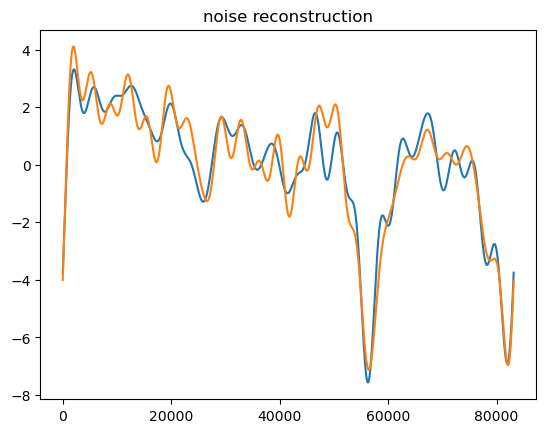

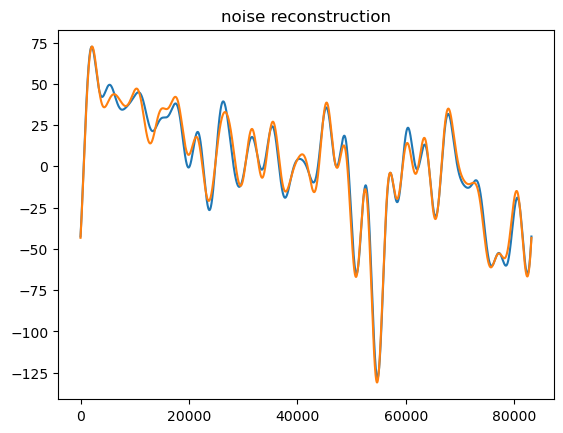

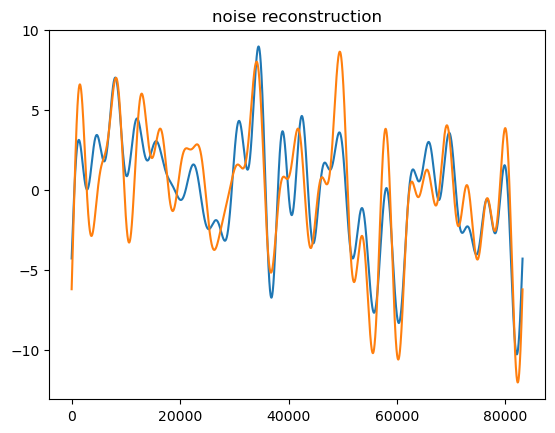

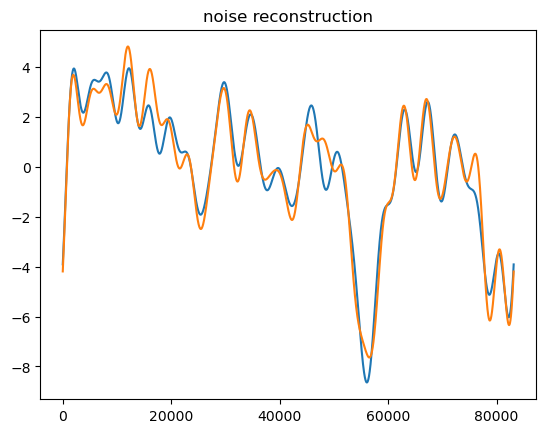

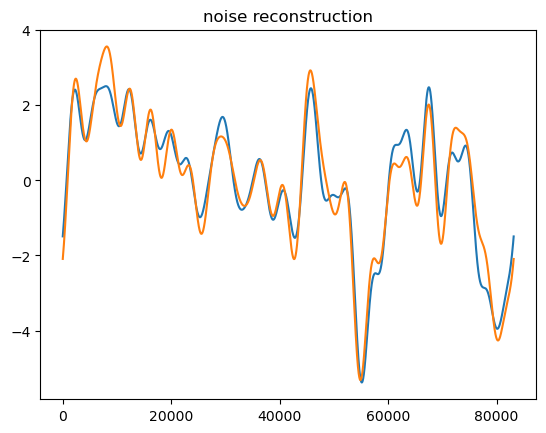

In [144]:
for i in range(20):
    plt.plot(common_noise[:,i], label="reconstructed (noise)")
    plt.plot(Xdo[:,i], label="lowpass original");
    plt.title("noise reconstruction")
    plt.show()
    

# 5. Generate denoised data as original - common noise

In [93]:
#denoised is the original minus the common low-frequency noise
X_denoised = data_matrix.T - common_noise


## check how it looks

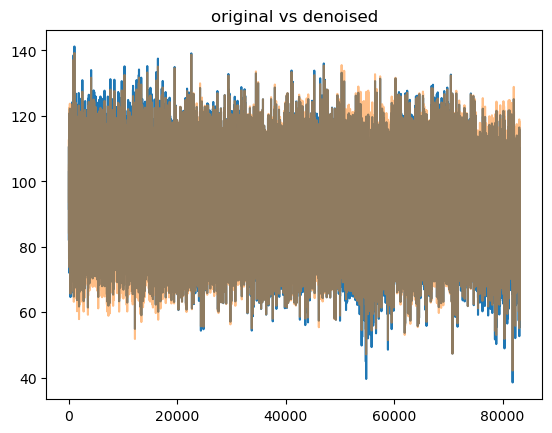

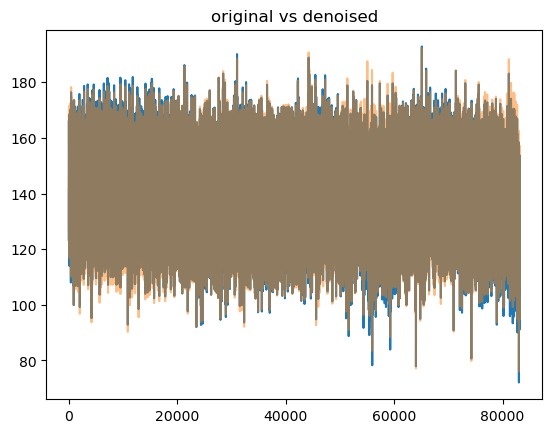

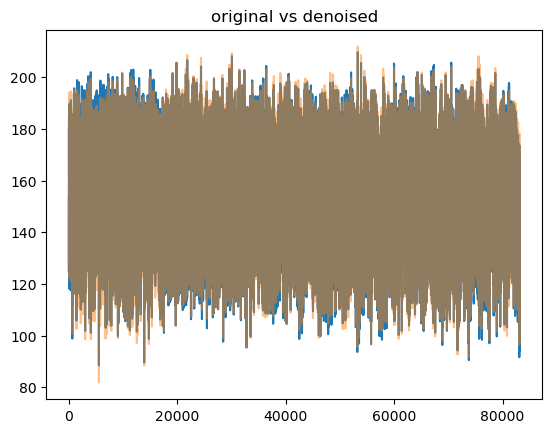

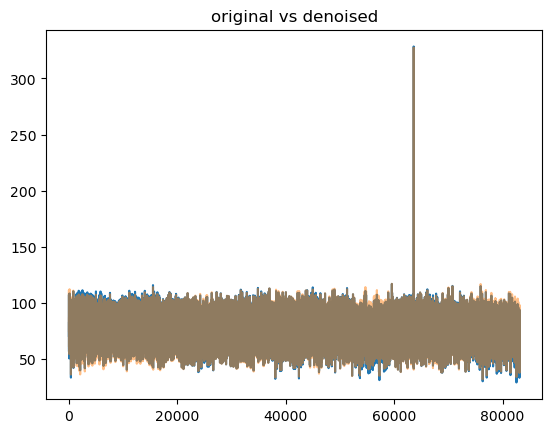

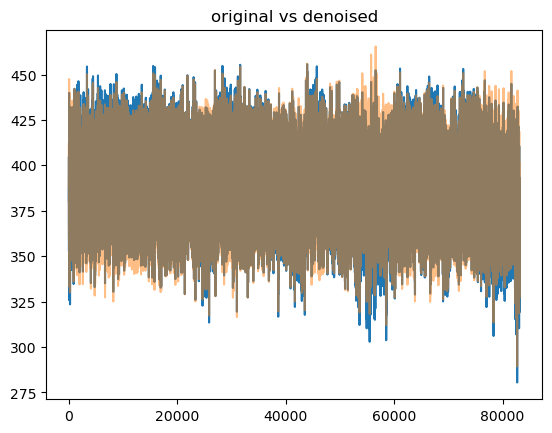

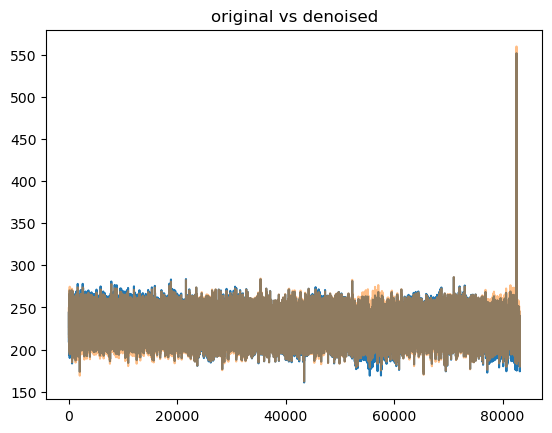

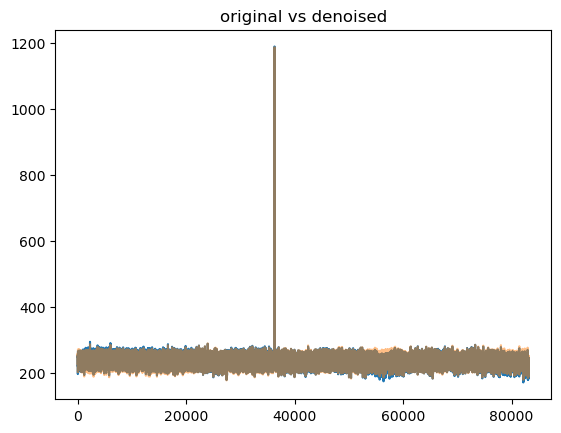

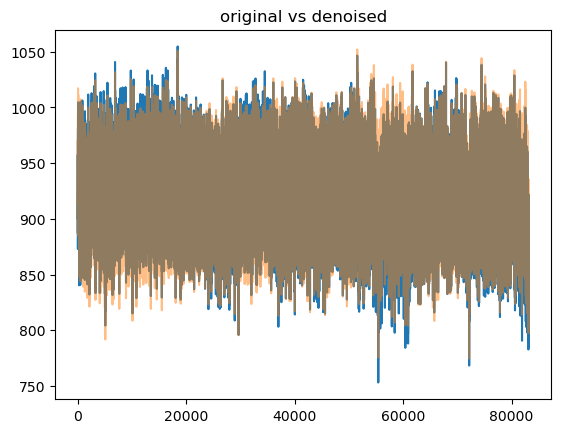

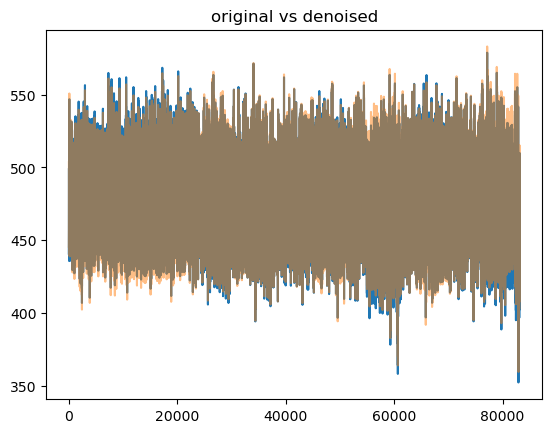

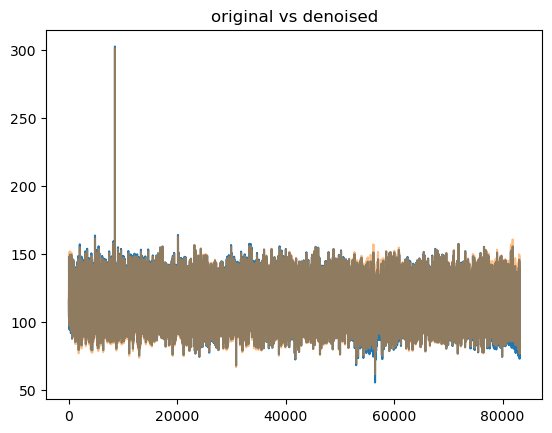

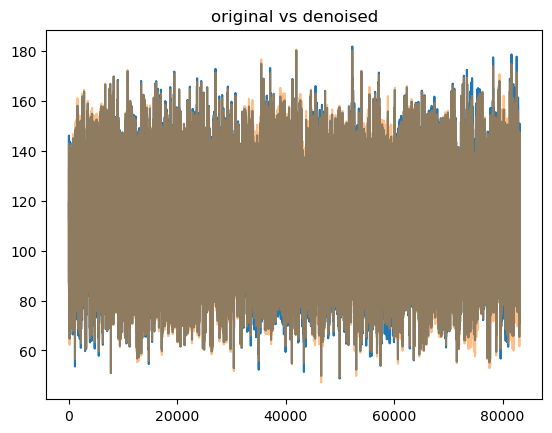

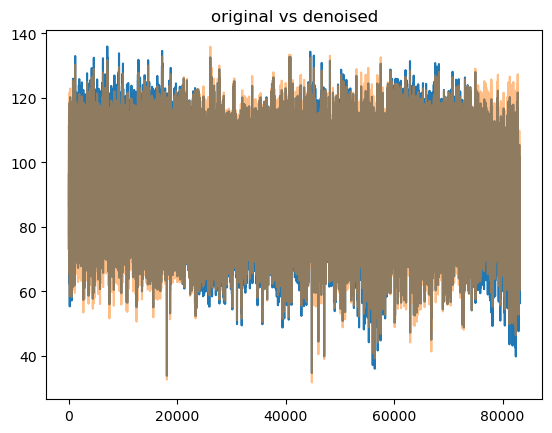

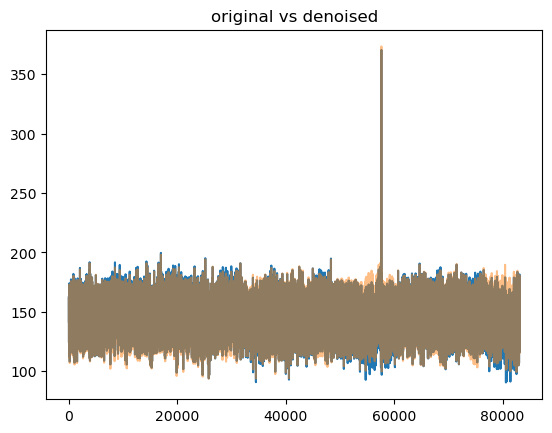

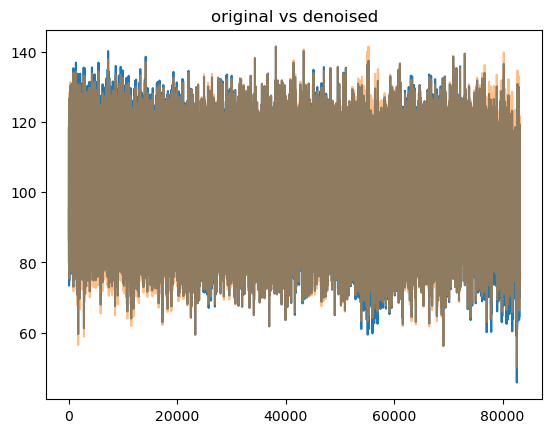

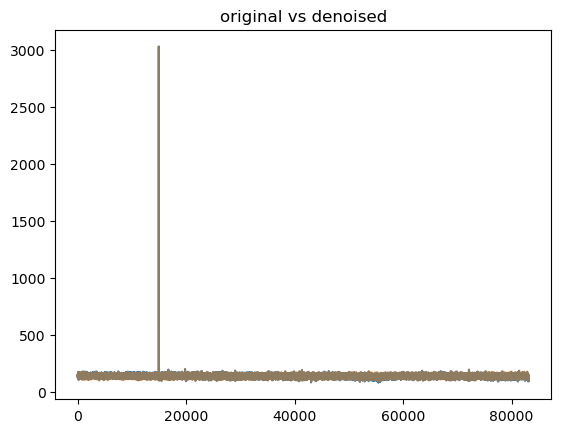

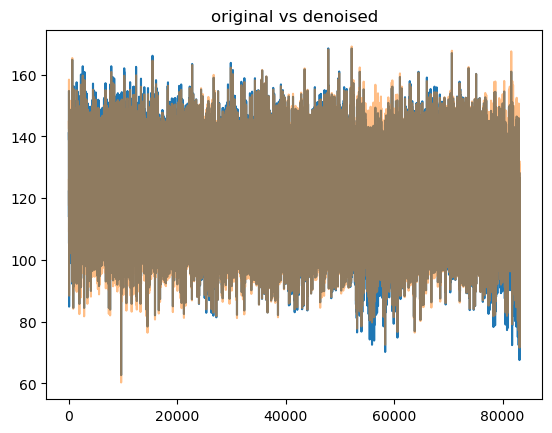

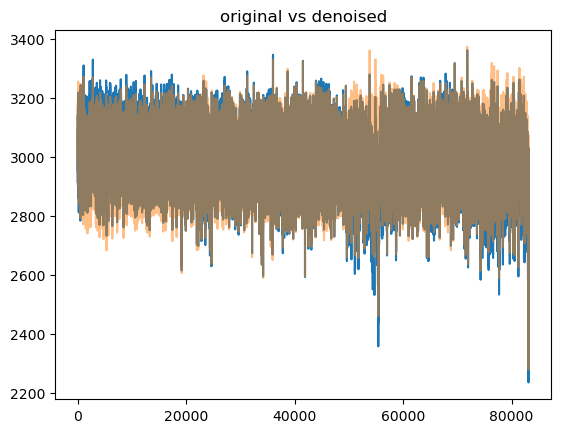

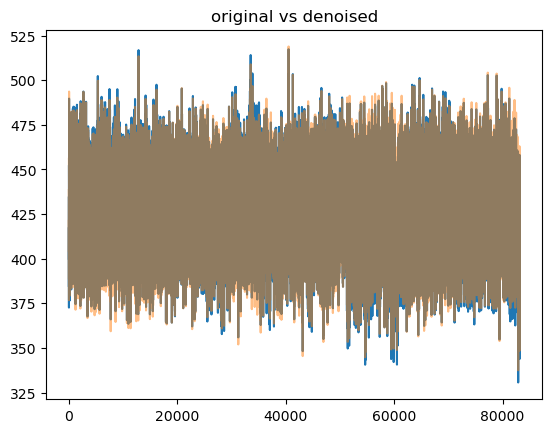

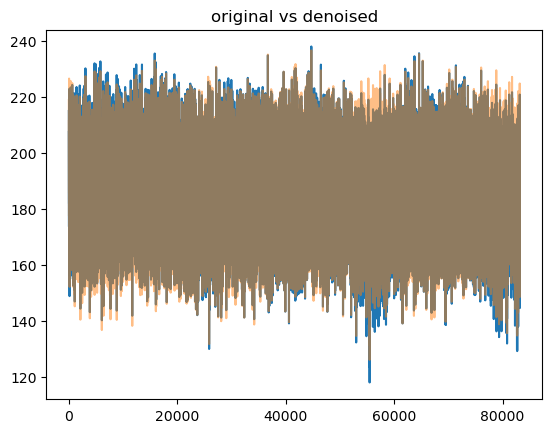

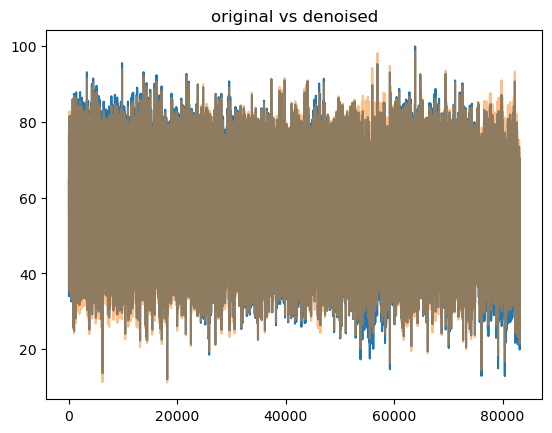

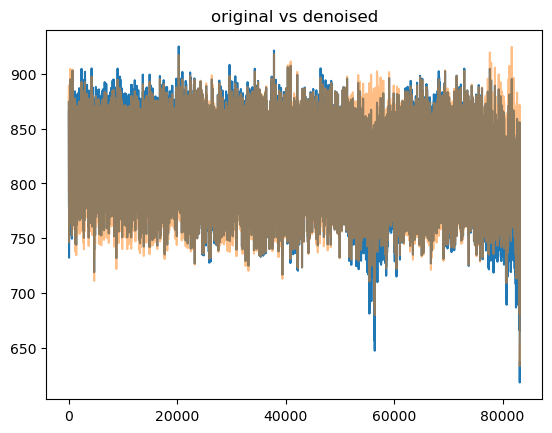

In [148]:
for i,l in enumerate(data_matrix):
    if i>20: break
    plt.plot(l);
    plt.plot(X_denoised[:,i], alpha=0.5);
    plt.title("original vs denoised")
    plt.show()
    

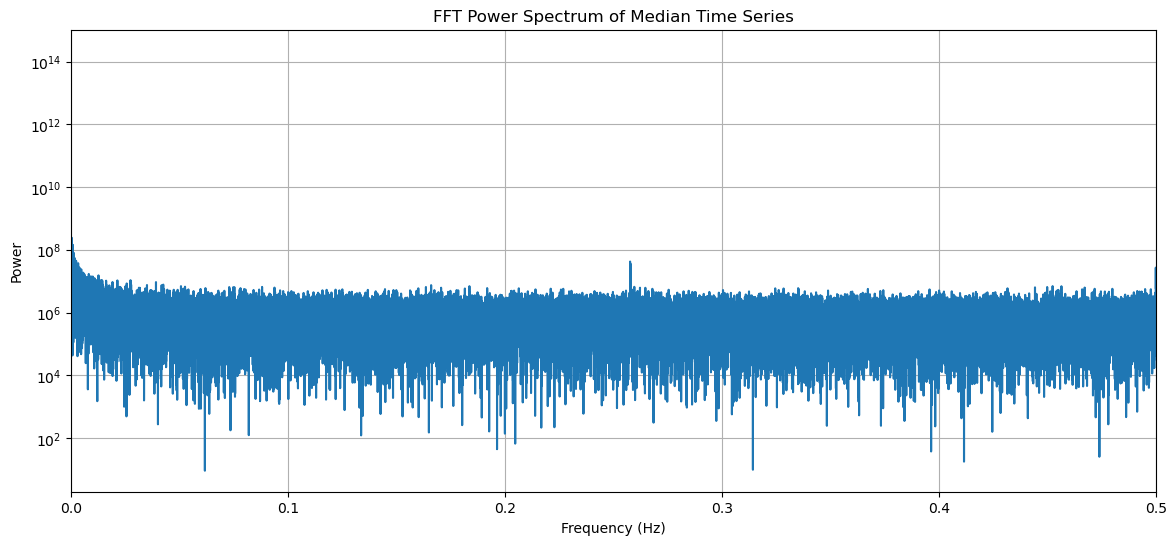

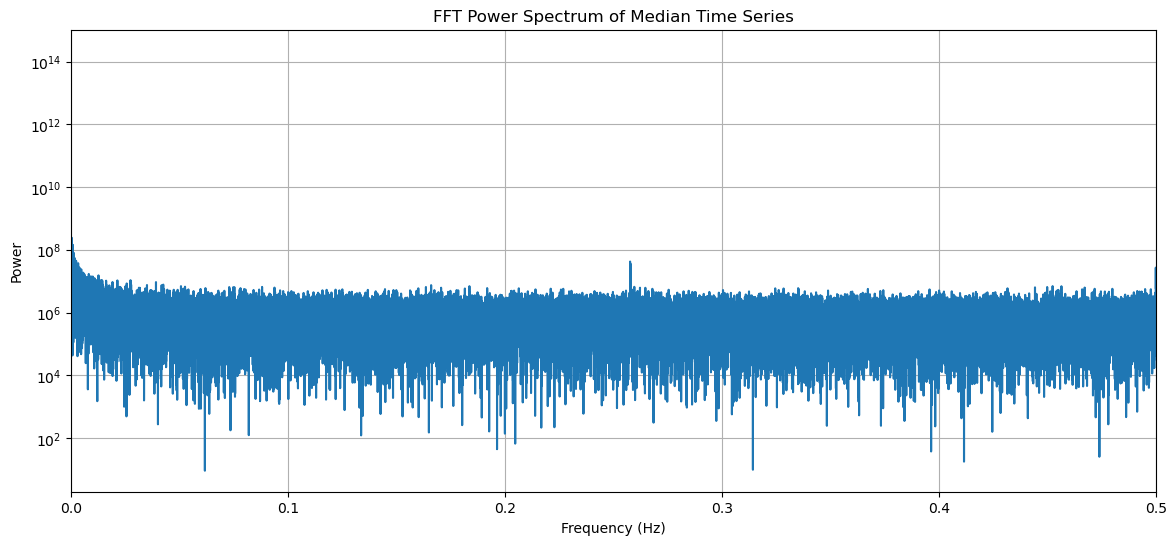

In [147]:
#median FFT

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()


fft_vals = fft(np.median(X_denoised, axis=1))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2
plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

spectrum does not change, noise is not periodic

Text(0.5, 1.0, 'originals')

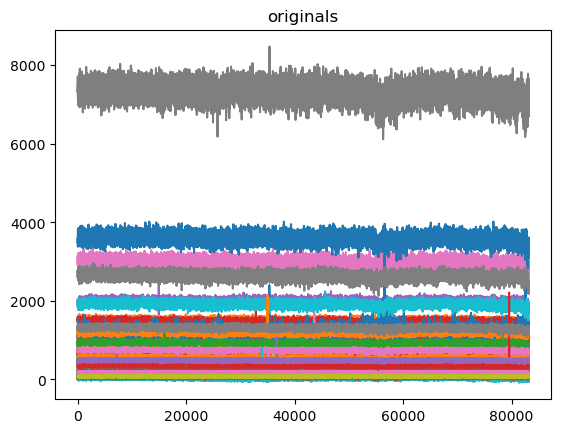

In [154]:
plt.plot(data_matrix.T);
plt.title("originals")

Text(0.5, 1.0, 'denoised')

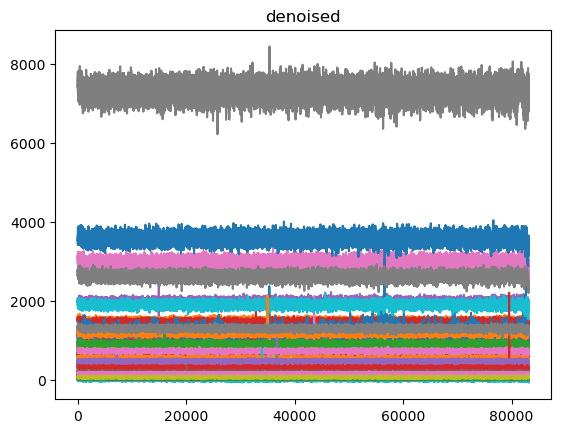

In [151]:
plt.plot(X_denoised);
plt.title("denoised")

(-15.0, 25.0)

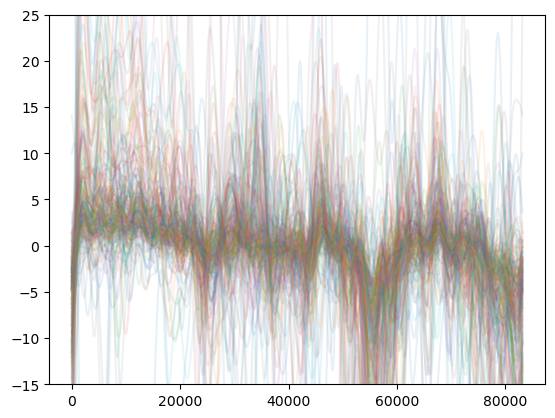

In [150]:
plt.plot(Xdo, alpha=0.1);
plt.ylim(-15,25)

X_denoised_centered = X_denoised - np.mean(X_denoised, axis=0)
plt.plot(X_denoised_centered, alpha=0.1);
plt.ylim(-15,25)

Text(0.5, 1.0, 'data median')

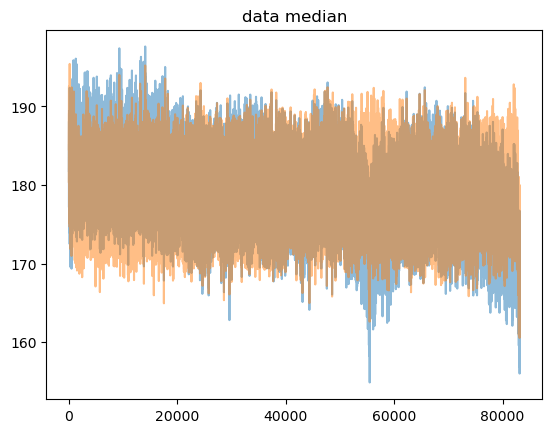

In [156]:
plt.plot(np.median(data_matrix.T, axis=1), alpha=0.5)
plt.plot(np.median(X_denoised, axis=1), alpha=0.5)
plt.title("data median")

data median looks stochastic

In [239]:
import numpy as np
from statsmodels.stats import diagnostic as diag


# Assume 'median_series' is your 1D array (83160 points)
# Test up to 10 lags (or 20, or 40)
lb_test = diag.acorr_ljungbox(np.median(data_matrix, axis=1), lags=[10,20,50,100,500,1000, 10000], return_df=True)
print(lb_test)

# Quick interpretation:
p_min = lb_test['lb_pvalue'].min()  # Look at the smallest p-value across lags
if p_min < 0.05:
    print(f"Strong structure detected (min p={p_min:.2e}). ")
else:
    print(f"Looks like pure white noise (p={p_min:.2e}).")


            lb_stat  lb_pvalue
10     1.791233e+05        0.0
20     3.402712e+05        0.0
50     7.636017e+05        0.0
100    1.392453e+06        0.0
500    5.518560e+06        0.0
1000   9.900244e+06        0.0
10000  3.762285e+07        0.0
Strong structure detected (min p=0.00e+00). 


In [240]:

# Assume 'median_series' is your 1D array (83160 points)
# Test up to 10 lags (or 20, or 40)
lb_test = diag.acorr_ljungbox(np.median(X_denoised, axis=1), lags=[10,20,50,100,500,1000, 10000], return_df=True)
print(lb_test)

# Quick interpretation:
p_max = lb_test['lb_pvalue'].max()  # Look at the smallest p-value across lags
if p_max < 0.05:
    print(f"Strong structure detected (min p={p_max:.10e}). ")
else:
    print(f"Looks like pure white noise (p={p_max:.10e}).")


             lb_stat  lb_pvalue
10      29648.576978        0.0
20      48619.667961        0.0
50      79652.479723        0.0
100    105074.917382        0.0
500    134927.140414        0.0
1000   142591.765773        0.0
10000  222224.414640        0.0
Strong structure detected (min p=0.0000000000e+00). 


there is still structure to a statistically significant level but decreased notably at all lags

In [166]:
original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/'

all_lcs = []
for file in os.listdir(original_direc):
    lc = np.load(original_direc+file)
    all_lcs.append(lc)

In [165]:
np.shape(np.array(all_lcs))

(110, 86240)

In [3]:
import numpy as np

In [5]:
file = np.load('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/lightcurve_ztf_20221020141806_000686_zi_c06_x_0000_1_1012_1438_time_adjusted_concat.npy')

In [6]:
file

array([134.5912323 , 143.84947205, 141.85147095, ..., 133.05104065,
       131.64245605, 152.80679321])

In [8]:
import os

In [74]:
all_lcs_names

array(['lightcurve_ztf_20221020141806_000686_zi_c06_x_0000_1_1012_1438_time_adjusted_concat.npy',
       'lightcurve_ztf_20221020154120_000640_zi_c05_x_0000_1_1146_2055_time_adjusted_concat.npy',
       'lightcurve_ztf_20221020154120_000640_zi_c11_x_0000_1_2423_1405_time_adjusted_concat.npy',
       ...,
       'lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0659_1017_time_adjusted_concat.npy',
       'lightcurve_ztf_20221020297847_000449_zr_c01_x_0000_4_2653_0526_time_adjusted_concat.npy',
       'lightcurve_ztf_20221020154120_000640_zi_c10_x_0000_2_2580_0530_time_adjusted_concat.npy'],
      dtype='<U87')

In [82]:
predictions_file='/lustre/lrspec/ZTF_data/random_forest_training/predictions_reupdated.csv' 
predictions = pd.read_csv(predictions_file, names=['filename', 'binary', 'rf'])
for i, row in predictions.iterrows():
    predictions.loc[i,'filename_new']=row['filename'][:46]+'0000'+row['filename'][50:62]+'_time_adjusted_concat.npy'
    


In [77]:
all_filestarts

array(['lightcurve_ztf_20221020138241_000686_zi_c09',
       'lightcurve_ztf_20221020138241_000686_zi_c10',
       'lightcurve_ztf_20221020138241_000686_zi_c11',
       'lightcurve_ztf_20221020138241_000686_zi_c12',
       'lightcurve_ztf_20221020138241_000686_zi_c13',
       'lightcurve_ztf_20221020138241_000686_zi_c14',
       'lightcurve_ztf_20221020138241_000686_zi_c15',
       'lightcurve_ztf_20221020138241_000686_zi_c16',
       'lightcurve_ztf_20221020141806_000686_zi_c01',
       'lightcurve_ztf_20221020141806_000686_zi_c02',
       'lightcurve_ztf_20221020141806_000686_zi_c03',
       'lightcurve_ztf_20221020141806_000686_zi_c04',
       'lightcurve_ztf_20221020141806_000686_zi_c05',
       'lightcurve_ztf_20221020141806_000686_zi_c06',
       'lightcurve_ztf_20221020141806_000686_zi_c07',
       'lightcurve_ztf_20221020141806_000686_zi_c08',
       'lightcurve_ztf_20221020141806_000686_zi_c09',
       'lightcurve_ztf_20221020141806_000686_zi_c10',
       'lightcurve_ztf_20221

In [84]:
predictions['filename'][0]

'lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv'

In [79]:
for filestart in all_filestarts:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]
    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist
    }
    df = pd.DataFrame.from_dict(lc_dict, orient='index')
    break

In [101]:
for i, row in predictions.iterrows():
    predictions.loc[i,'filename_new']=row['filename'][:46]+'0000'+row['filename'][50:62]+'_time_adjusted_concat.npy'
    


KeyboardInterrupt: 

In [109]:
predictions

,filename,binary,rf,filename_new
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,0,0.314823,lightcurve_ztf_20221020138241_000686_zi_c11_x_...
480362,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,0,0.012341,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
480363,lightcurve_ztf_20221020297847_000449_zr_c07_x_...,0,0.012842,lightcurve_ztf_20221020297847_000449_zr_c07_x_...
480364,lightcurve_ztf_20221020138241_000686_zi_c14_x_...,0,0.039716,lightcurve_ztf_20221020138241_000686_zi_c14_x_...
480365,lightcurve_ztf_20221020157697_000640_zi_c03_x_...,0,0.143241,lightcurve_ztf_20221020157697_000640_zi_c03_x_...
...,...,...,...,...
301348,lightcurve_ztf_20221020141806_000686_zi_c10_x_...,1,0.924374,lightcurve_ztf_20221020141806_000686_zi_c10_x_...
168858,lightcurve_ztf_20221020148032_000686_zg_c14_x_...,1,0.750051,lightcurve_ztf_20221020148032_000686_zg_c14_x_...
396735,lightcurve_ztf_20221020157697_000640_zi_c16_x_...,1,0.938150,lightcurve_ztf_20221020157697_000640_zi_c16_x_...
640880,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,1,0.811776,lightcurve_ztf_20221020148032_000686_zg_c07_x_...


In [108]:
predictions = predictions.sort_values('binary')

In [110]:
pred_no_dup = predictions.drop_duplicates(subset='filename_new', keep='last')

In [113]:
import matplotlib.pyplot as plt

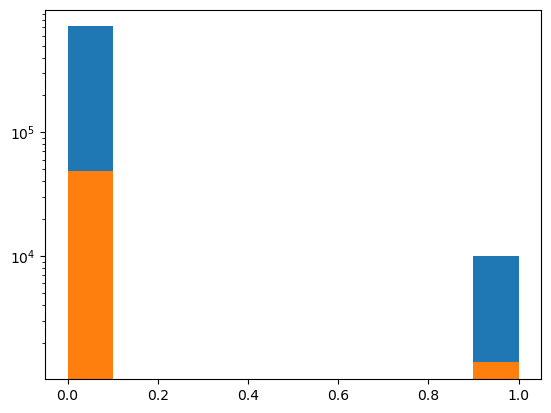

In [117]:
plt.hist(predictions['binary'])
plt.hist(pred_no_dup['binary'])
plt.yscale('log')

In [118]:
predictions_file = '/lustre/lrspec/ZTF_data/random_forest_training/predictions_reupdated.csv'
predictions = pd.read_csv(predictions_file, names=['filename', 'binary', 'rf'])

predictions['filename_new'] = (
    predictions['filename'].str[:46]
    + '0000'
    + predictions['filename'].str[50:62]
    + '_time_adjusted_concat.npy'
)

In [123]:
predictions.to_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_w_fname.csv')

In [128]:
original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/'

all_filestarts = np.load('/home/3155/all_filestarts.npy')
#need to do it per-chip
for filestart in all_filestarts:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]
    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist if np.sum(predictions[predictions['filename_new']==file]['binary']<1)
    }
    df = pd.DataFrame.from_dict(lc_dict, orient='index')  # rows=filenames, cols=time points
    break

In [132]:
np.sum(predictions[predictions['filename_new']==file]['binary'].values)

0

In [104]:
file = predictions['filename_new'][0]

In [107]:
np.sum(predictions[predictions['filename_new']==file]['binary'])

0

In [94]:
'lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy'[50:62]

'_4_0999_2857'

In [9]:
original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/'

all_lcs_names = [file for file in os.listdir(original_direc)]
#need to do it per-chip
# for chip in chip_list:
#     lc_dict = {
#         file: np.load(os.path.join(original_direc, file))
#         for file in os.listdir(original_direc)
#     }
#     df = pd.DataFrame.from_dict(lc_dict, orient='index')  # rows=filenames, cols=time points

In [11]:
all_lcs_names = np.array(all_lcs_names)

In [16]:
'lightcurve_ztf_20221020141806_000686_zi_c06_x_0000_1_1012_1438_time_adjusted_concat.npy'[:43]

'lightcurve_ztf_20221020141806_000686_zi_c06'

In [17]:
all_filestarts = []
for filename in all_lcs_names:
    filestart = filename[:43]
    all_filestarts.append(filestart)

In [19]:
all_filestarts = np.unique(all_filestarts)

In [21]:
np.save('/home/3155/all_filestarts.npy', all_filestarts)

In [22]:
filelist = [file for file in os.listdir(original_direc) if file.startswith(all_filestarts[0])]

In [25]:
import pandas as pd

In [26]:
original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/'

all_filestarts = np.load('/home/3155/all_filestarts.npy')
#need to do it per-chip
for filestart in all_filestarts:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]
    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist if np.sum(predictions[predictions['filename_new']==file]<1)
    }
    df = pd.DataFrame.from_dict(lc_dict, orient='index')  # rows=filenames, cols=time points
    
    print('shape df: ', np.shape(df))
        
    data_matrix = df
    df_lowpass = pd.DataFrame(
            [apply_fft_lowpass(data_matrix.T[:, i], 1, fc=0.0003) for i in range(data_matrix.T.shape[1])]
        )
    

shape df:  (323, 86240)


NameError: name 'apply_fft_lowpass' is not defined

In [27]:
def apply_fft_lowpass(data, fs=1, fc=0.0003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))

In [42]:
from scipy.fft import fft, ifft, fftfreq

In [39]:
data_matrix.iloc[0]

0         78.231003
1         71.507629
2        100.590042
3        102.921478
4         93.089218
            ...    
86235    105.271973
86236     68.738754
86237     66.714294
86238     83.548599
86239     60.278915
Name: lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy, Length: 86240, dtype: float64

In [41]:
apply_fft_lowpass(data_matrix.iloc[0], 1, fc=0.0003)

NameError: name 'fft' is not defined

In [34]:
data_matrix.T[:, 0]

InvalidIndexError: (slice(None, None, None), 0)

In [45]:
data_matrix.T.shape[1]

323

In [50]:
apply_fft_lowpass(data_matrix.iloc[1].values, 1, fc=0.0003) 

array([94.79116678, 94.79051328, 94.78985967, ..., 94.79312654,
       94.7924734 , 94.79182015])

In [47]:
data_matrix.iloc[0]

0         78.231003
1         71.507629
2        100.590042
3        102.921478
4         93.089218
            ...    
86235    105.271973
86236     68.738754
86237     66.714294
86238     83.548599
86239     60.278915
Name: lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy, Length: 86240, dtype: float64

In [51]:
data_matrix = df
df_lowpass = pd.DataFrame(
        [apply_fft_lowpass(data_matrix.iloc[i].values, 1, fc=0.0003) for i in range(data_matrix.T.shape[1])]
    )


KeyboardInterrupt: 

In [29]:
data_matrix

,0,1,2,3,4,5,6,7,8,9,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy,78.231003,71.507629,100.590042,102.921478,93.089218,87.480072,77.263794,81.156754,76.711807,63.963379,...,85.789795,86.424347,75.027847,68.124863,68.242401,105.271973,68.738754,66.714294,83.548599,60.278915
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0891_2120_time_adjusted_concat.npy,109.486862,105.008194,78.009949,95.767380,105.716751,96.861984,104.105316,86.577362,97.015076,78.999908,...,82.101898,87.627045,74.301285,84.995880,78.178452,101.308792,80.868301,117.145554,98.225189,110.216965
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2225_1757_time_adjusted_concat.npy,221.950378,218.365982,220.449860,218.932129,203.490936,189.315643,188.916916,214.515137,195.260925,202.389420,...,195.561462,199.424927,202.030014,210.517914,191.736343,176.000916,174.951981,192.916183,197.969711,185.982224
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0491_2051_time_adjusted_concat.npy,264.710083,252.494415,274.001526,277.595032,241.624435,261.857544,265.386353,257.989868,259.092896,272.313568,...,241.284470,251.920898,266.797546,255.387299,277.474792,240.906860,240.960495,277.921387,235.414963,249.015182
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2548_1441_time_adjusted_concat.npy,835.952209,880.951965,870.973877,887.825867,888.946777,912.621094,894.514648,867.233215,887.867554,900.881592,...,904.800171,874.278381,874.275818,890.239258,894.959167,857.083008,827.257507,849.570374,887.795654,888.652954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_2_1648_2219_time_adjusted_concat.npy,151.560928,164.645432,168.234467,145.703201,126.642990,165.116135,154.729218,144.817520,188.077759,151.644211,...,193.619400,190.508987,178.698151,199.530930,157.829895,190.266357,211.608841,204.512817,200.967728,191.511581
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0317_2664_time_adjusted_concat.npy,88.426483,97.660660,89.678146,90.064606,94.370132,107.487244,88.042908,84.395538,78.857681,97.295593,...,103.408676,80.839401,80.373627,68.073761,91.608795,70.572693,69.788071,80.126495,85.985977,88.144913
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_1201_1459_time_adjusted_concat.npy,1942.505249,1890.314575,1928.879395,1937.766846,1882.677979,1859.938354,1890.431641,1871.691162,1874.831787,1821.470337,...,1888.394897,1916.133911,1963.422485,1895.280029,1883.098633,1937.537842,1981.636108,1963.747559,1915.965698,1988.556396
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_3029_1435_time_adjusted_concat.npy,194.449448,161.635574,178.784012,186.406067,149.043884,193.025223,187.526276,166.567703,188.795166,184.401398,...,172.901550,164.904602,186.958282,170.323059,183.865982,160.354324,173.877838,178.351868,176.736557,191.158005


In [72]:
df = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/lightcurve_ztf_20221020138241_000686_zi_c12_x_0000_3_2617_1104_time_adjusted_concat_denoised')

In [73]:
df

,0
0,lightcurve_ztf_20221020138241_000686_zi_c12_x_...
1,58.32252836234861
2,82.1211959065135
3,52.97409182096701
4,58.734792763049
...,...
86236,81.62737276449889
86237,59.66019321460683
86238,61.88919456380784
86239,60.71638486590143


In [58]:
big_df = pd.read_csv('/lustre/lrspec/ZTF_data/df_denoised_temp')

In [59]:
big_df

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
0,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,58.322528,82.121196,52.974092,58.734793,47.397073,66.238216,80.569622,71.082453,55.876000,...,79.136514,84.704436,63.537875,72.557257,67.531395,81.627373,59.660193,61.889195,60.716385,72.896342
1,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,91.887655,70.947909,57.974629,81.363673,75.611533,98.068916,57.141339,73.580940,80.144141,...,56.272906,103.026473,72.630157,93.185018,80.990234,92.860732,79.653842,77.161770,87.499858,92.704206
2,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,-5.385817,-5.075687,2.334645,5.577860,1.031461,8.267637,-1.597813,20.015785,-11.751693,...,-4.384003,3.534030,3.266834,4.227465,-0.967195,3.324852,5.655333,10.127323,5.571920,11.681065
3,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,543.140405,579.195411,577.803941,570.364860,550.018547,588.000478,566.954390,598.063449,557.834186,...,591.593783,577.702724,579.519668,581.468506,568.166607,589.581134,578.825980,585.414816,568.529221,604.392280
4,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,265.204542,236.442206,244.656398,224.949370,244.086303,238.831281,256.141991,230.794160,235.570533,...,191.807717,188.348458,188.642203,221.011385,205.013026,196.178423,233.069876,190.337730,213.581367,207.494816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,627.301203,633.818362,689.245122,633.507814,630.564323,652.434364,652.664079,647.602101,652.134050,...,648.017042,628.501058,644.864828,642.014175,646.481510,642.200914,629.769556,667.732723,662.430747,661.590801
400,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,335.925548,352.668941,350.460372,373.954810,363.314610,350.892738,349.674118,332.278015,344.556845,...,364.920350,352.130167,320.856187,364.346701,362.023525,373.962739,344.576635,367.690106,364.783741,360.529173
401,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,48.502221,55.896083,56.896177,78.274964,64.543796,63.477805,44.952768,53.124021,34.986635,...,59.048798,43.348267,46.565933,51.503372,69.507905,47.173189,48.633868,38.076633,52.061879,38.494452
402,lightcurve_ztf_20221020138241_000686_zi_c12_x_...,154.919484,143.123353,165.022350,165.532703,145.018579,140.060133,137.439301,149.221161,168.489806,...,147.316436,144.371703,144.063825,158.751336,140.589801,142.178584,130.367891,166.108098,151.897422,147.481101


In [61]:
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/'
for i, row in big_df.iterrows():
    row.to_csv(os.path.join(new_direc, row['Unnamed: 0'][:-4]+'_denoised'), header=True, index=False)
    print(os.path.join(new_direc, row['Unnamed: 0'][:-4]+'_denoised'))
    break

/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/lightcurve_ztf_20221020138241_000686_zi_c12_x_0000_3_2617_1104_time_adjusted_concat_denoised


In [134]:
the_final_df = pd.read_csv('/lustre/lrspec/ZTF_data/final_df_temp')

In [143]:

def get_tot_csv(
    df,
    index, lc_filename=None,
    half_aperture=2, lcfpath='/lustre/lrspec/ZTF_data/lightcurves/1020/'  
):
    """
    returns tot, maxcols: an array that is the flux of the star streak
    given an aperture that is halfaperture*2+1
    and if tracking=true, tracks when the streak posittion fluctuates
    oif tracking==false, goes based on average center of streak
    put in lc_filename yourself or it will take it from the dataframe 
    (in which case df and index are ignored)
    """
    # Handle filename logic 
    if lc_filename == None:
        lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
        df_row = df.loc[index]
        lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'
        
    if lcfpath == '/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos/':
         lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'._'+str(df_row['quad'])+'.npy'+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+".csv"
    elif lcfpath == '/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg/':
         lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'._'+str(df_row['quad'])+'.npy'+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+".csv"
            
    if lcfpath==None:
        lcfpath = '/lustre/lrspec/ZTF_data/lightcurves/1020/'  
    lc_df = pd.read_csv(lcfpath + lc_filename)
    
    # Calculate flux and error
    tot = lc_df['flux_hap_'+str(half_aperture)]
    maxcols = lc_df['max_col']

    return tot, maxcols




def get_tot_csv_filtered_hap2(
    df,
    index, lc_filename=None,
    lcfpath='/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'  
):
    """
    returns tot, maxcols: an array that is the flux of the star streak
    given an aperture that is halfaperture*2+1
    and if tracking=true, tracks when the streak posittion fluctuates
    oif tracking==false, goes based on average center of streak
    put in lc_filename yourself or it will take it from the dataframe 
    (in which case df and index are ignored)
    """
    # Handle filename logic 
    if lc_filename == None:
        lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
        df_row = df.loc[index]
        lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+"_filtered_hap2.csv"
    if lcfpath == '/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos_filtered/':
         lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'._'+str(df_row['quad'])+'.npy'+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+"_filtered_hap2.csv"
    elif lcfpath == '/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/lightcurves_neg_filtered/':
         lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'._'+str(df_row['quad'])+'.npy'+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+"_filtered_hap2.csv"
       
    # if lcfpath==None:
    #     lcfpath = '/lustre/lrspec/ZTF_data/lightcurves/1020/'  
    lc_df = pd.read_csv(lcfpath + lc_filename)
    
    # Calculate flux and error
    tot = pd.read_csv(lcfpath + lc_filename)['flux_hap_2']

    return np.array(tot)

In [145]:
the_final_df

,Unnamed: 0.11,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,...,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point,snr_local_filtered2
0,81397,81397,81397,81397,81397,81397,81397,81397,81397,81397,...,39.683822,107.819591,44.632009,1.0,-6.680719,115.0,81397,3.237893,125.0,1.207826
1,245962,245962,245962,245962,245962,245962,245962,245962,245962,245962,...,31.760438,385.537280,-18.327661,1.0,4.281082,115.0,245962,2.546952,126.0,0.300787
2,41671,41671,41671,41671,41671,41671,41671,41671,41671,41671,...,15.774645,322.668190,-18.826869,39.0,33.857827,394.0,41671,2.535315,394.0,0.602963
3,229517,229517,229517,229517,229517,229517,229517,229517,229517,229517,...,10.360263,109.919761,-26.524889,1.0,5.150232,3015.0,229517,2.357054,3014.0,0.389910
4,50051,50051,50051,50051,50051,50051,50051,50051,50051,50051,...,26.228510,527.437645,-33.896351,4.0,12.692104,3008.0,50051,2.345076,3023.0,0.519254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,346461,346461,346461,346461,346461,346461,346461,346461,346461,346461,...,24.979819,364.258629,-76.284807,6.0,18.823204,3015.0,346461,1.367968,3015.0,0.409674
96,156561,156561,156561,156561,156561,156561,156561,156561,156561,156561,...,61.434349,2224.305367,-197.956417,24.0,62.746495,1829.0,156561,1.367447,1829.0,0.456963
97,247129,247129,247129,247129,247129,247129,247129,247129,247129,247129,...,25.920688,505.043351,-67.198363,23.0,35.316034,2130.0,247129,1.364586,2130.0,0.361175
98,172339,172339,172339,172339,172339,172339,172339,172339,172339,172339,...,21.270230,523.951872,-55.962820,15.0,26.780549,730.0,172339,1.362636,730.0,0.237632


1726.0
100.0
lightcurve_ztf_20221020148032_000686_zg_c07_x_0000_1_1726_0100_time_adjusted_concat_denoised
couldnt get tot denoised
1698.0
805.0
lightcurve_ztf_20221020157697_000640_zi_c12_x_0000_3_1698_0805_time_adjusted_concat_denoised
couldnt get tot denoised
1714.0
663.0
lightcurve_ztf_20221020163819_000640_zg_c13_x_0000_2_1714_0663_time_adjusted_concat_denoised
107.0
1096.0
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_0107_1096_time_adjusted_concat_denoised
1710.0
1703.0
lightcurve_ztf_20221020154120_000640_zi_c15_x_0000_2_1710_1703_time_adjusted_concat_denoised
1726.0
100.0
lightcurve_ztf_20221020148032_000686_zg_c07_x_0000_1_1726_0100_time_adjusted_concat_denoised
couldnt get tot denoised
265.0
187.0
lightcurve_ztf_20221020163819_000640_zg_c13_x_0000_4_0265_0187_time_adjusted_concat_denoised
231.0
2852.0
lightcurve_ztf_20221020163819_000640_zg_c14_x_0000_4_0231_2852_time_adjusted_concat_denoised
231.0
2852.0
lightcurve_ztf_20221020163819_000640_zg_c14_x_0000_4_0231_2852_t

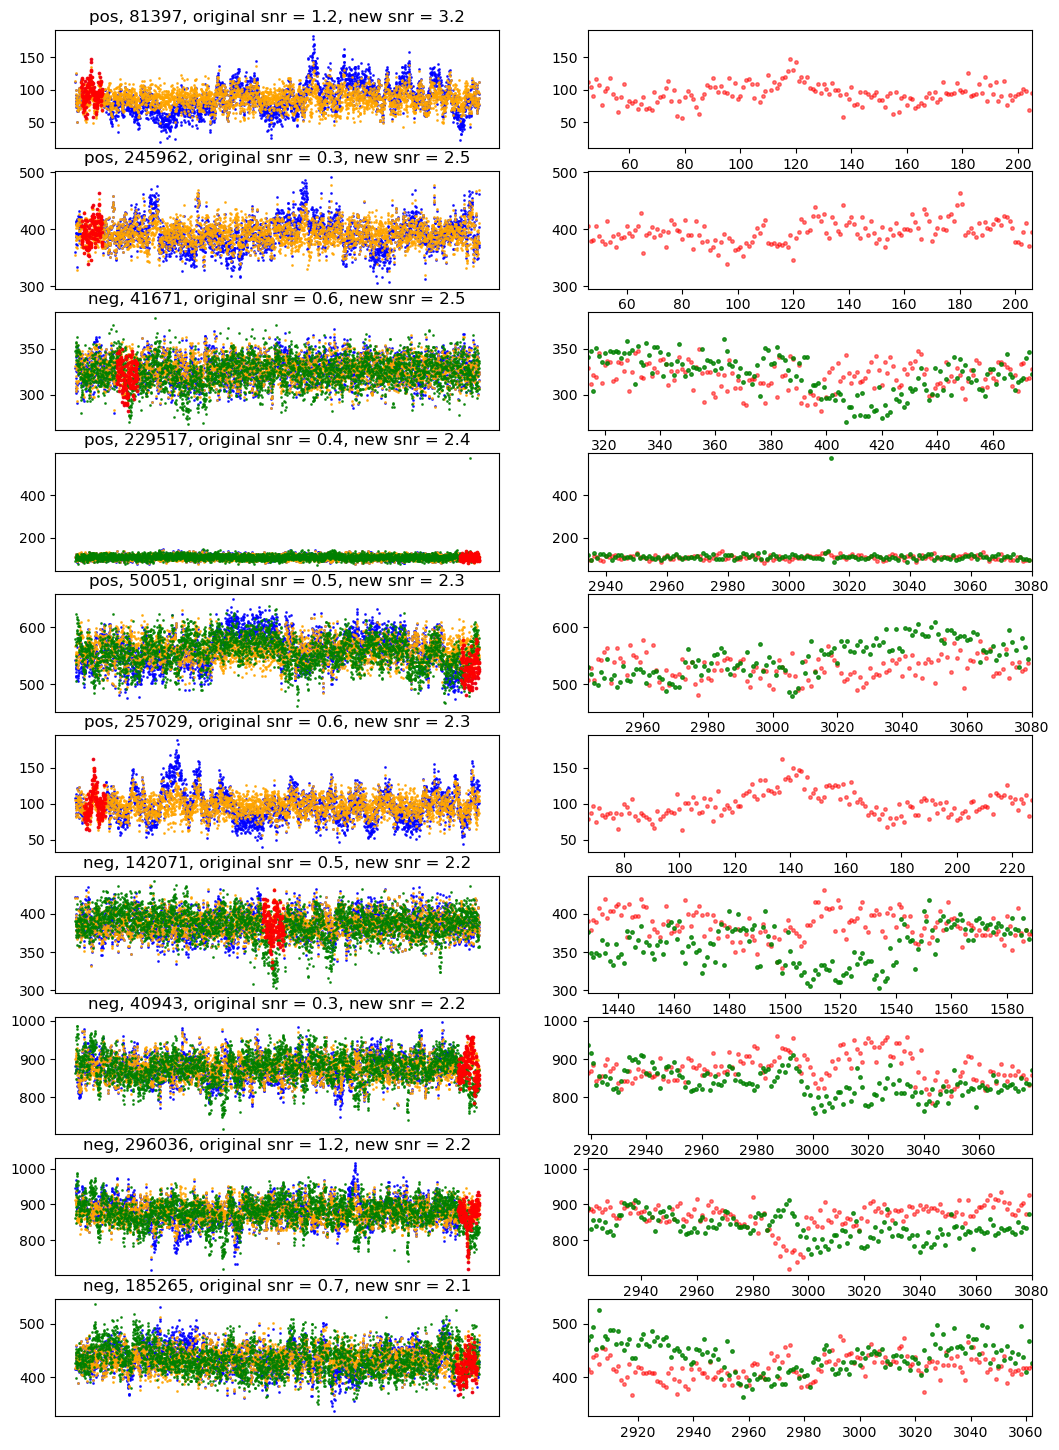

In [144]:
size = 160
# new = final_df_rfgood_filtered.loc[indices_to_plot]
# df = final_df_rfgood_filtered.loc[indices_to_plot]
df = the_final_df[:10]
figrows = len(df)
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    print(df.loc[index,'closest_x'])
    print(df.loc[index,'closest_y'])
    tot, maxols = get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8, c='blue')
    tot_filt = get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8, c='orange')
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(
        df.loc[index, "concat_index_copy"])+", original snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}"+", new snr = "+f"{df.loc[index, 'snr_local_denoised']:.1f}"
                     )
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.5, c='red')
    
    try:
        if str(df.loc[index, "real_type_local"])=='pos':
            range1 = np.max([int(df.loc[index, 'central_point_brightening_denoise']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_brightening_denoise']+size//2-1), len(tot)-1])
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, xes)
            # print(range1, range2, len(tot), len(tot[range1:range2+1]))
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
        elif str(df.loc[index, "real_type_local"])=='neg':
            
            range1 = np.max([int(df.loc[index, 'central_point_dimming_denoised']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_dimming_denoised']+size//2-1), len(tot)-1])
            # print(range1, range2, len(tot), len(tot[range1:range2+1]), len(xes))
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, xes)
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
            
            # xes = np.linspace(df.loc[index, 'central_point_dimming_filtere']-size//2,df.loc[index, 'central_point_dimming_filtere']+size//2-1,2*(size//2))
            # # print(len(xes))
            # # print(xes)
            # ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-size//2, df.loc[index, 'central_point_dimming_filtere']+size//2)
            # ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-size//2:int(df.loc[index, 'central_point_dimming_filtere'])+size//2],  s=15, alpha=.8, c='red', zorder=10)
    except TypeError:
        pass
    try:
        tot_denoised = get_tot_denoised(df, index)
        ax[i,0].plot(tot_denoised, '.', ms=2, alpha=.8, c='green')
        ax[i,1].plot(tot_denoised, '.', ms=5, alpha=.8, c='green')
    except:
        print("couldnt get tot denoised")
plt.show()

In [140]:
def get_tot_denoised(df, i, cut=True):
    filename = 'lightcurve_'+df.loc[i, 'filename'][:-5]+'0000_'+str(df.loc[i, 'quad'])+'_'+f'{int(df.loc[i,"closest_x"]):04}'+'_'+f'{int(df.loc[i,"closest_y"]):04}'+'_time_adjusted_concat_denoised'
    print(filename)
    anarray = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/'+filename, header=None).values.flatten()
    if cut==False:
        return anarray
    else:
        number = int(df.loc[i, 'filename'][-5:-1])
        num = 1
        return anarray[num*3080:(num+1)*3080] #possibly one pixel off but should be close enough for SNR

In [137]:
importlib.reload(rff)

NameError: name 'rff' is not defined

In [133]:
lc = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/lightcurve_ztf_20221020148032_000686_zg_c07_x_0000_1_1726_0100_time_adjusted_concat_denoised')

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/lightcurve_ztf_20221020148032_000686_zg_c07_x_0000_1_1726_0100_time_adjusted_concat_denoised'

In [5]:
import os

In [8]:
predictions = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_w_fname.csv')



def apply_fft_lowpass(data, fs=1, fc=0.0003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))


original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/'

all_filestarts = np.load('/home/3155/all_filestarts.npy')
#need to do it per-chip
# for filestart in all_filestarts:
filestart='lightcurve_ztf_20221020297847_000449_zr_c12'
if 1==1:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]
    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist if np.sum(predictions[predictions['filename_new']==file]['binary'].values)<1
    }
    df = pd.DataFrame.from_dict(lc_dict, orient='index')  # rows=filenames, cols=time points
    
    print(filestart, flush=True)
    print('shape df: ', np.shape(df), flush=True)
        
    data_matrix = df
    df_lowpass = pd.DataFrame(
            [apply_fft_lowpass(data_matrix.iloc[i].values, 1, fc=0.0003) for i in range(data_matrix.T.shape[1])]
        )
    
    # print('shape df_lowpass: ', np.shape(df_lowpass))
    
    X = df_lowpass.values.T
    X_centered = X - np.mean(X, axis=0)
    Xdo = X_centered
    
    # print('shape Xdo: ', np.shape(Xdo))
    
    # scaler = StandardScaler()
    # X_scaled = scaler.fit_transform(X_centered)
    #IF YOU WANT TO SCALE
    #Xdo = X_scaled
    
    pca = PCA()
    pca.fit(Xdo)
    
    k = 10
    pca_noise = PCA(n_components=k)
    pca_noise.fit(Xdo)
    # the common noise is the 20-components reconstructions of the lowpass data
    common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))
    
    X_denoised = data_matrix.T - common_noise
    
    # print('shape X_denoised: ', np.shape(X_denoised))
    
    df_denoised = pd.DataFrame(X_denoised.T, index=df.index, columns=df.columns)
    # df_denoised.to_csv('/lustre/lrspec/ZTF_data/df_denoised_temp')
    
    # for i, row in df_denoised.iterrows():
    #     row.to_csv(os.path.join(new_direc, i[:-4]+'_denoised'), header=False, index=False)

lightcurve_ztf_20221020297847_000449_zr_c12
shape df:  (79, 86240)


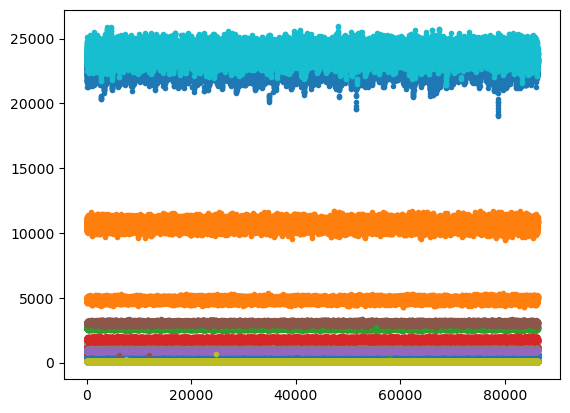

In [12]:
for i, row in df_denoised.iterrows():
    plt.plot(row, '.')

In [ ]:
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_0107_1096_time_adjusted_concat_denoised

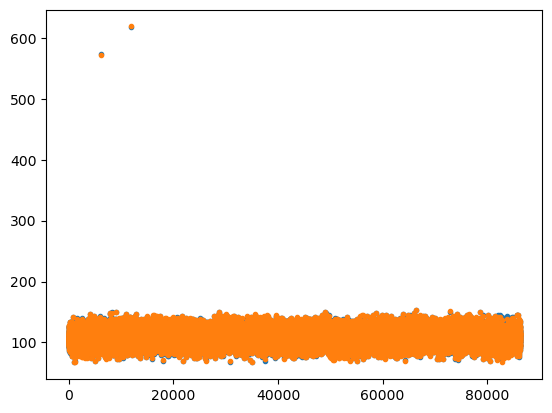

In [18]:
plt.plot(df_denoised.loc['lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_0107_1096_time_adjusted_concat.npy'], '.')
plt.plot(df.loc['lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_0107_1096_time_adjusted_concat.npy'], '.')


In [15]:
df_denoised[-4:]

,0,1,2,3,4,5,6,7,8,9,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_1242_1455_time_adjusted_concat.npy,859.919778,889.370232,860.445400,878.224931,893.485194,895.631766,874.188695,894.048011,893.886409,904.497043,...,947.270725,984.341481,953.973534,937.976028,939.813257,903.403007,876.049781,925.918010,918.239626,877.185345
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_4_0107_1096_time_adjusted_concat.npy,113.373385,110.394985,115.311088,99.704672,108.423026,112.903010,109.545227,117.611671,104.679690,104.968765,...,114.100902,107.558377,112.550430,109.897146,112.724271,105.576348,114.652639,95.776189,101.294425,119.119258
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_3_1964_0788_time_adjusted_concat.npy,124.440783,96.837232,74.527002,107.402565,103.869987,97.349572,99.689892,111.563614,101.495748,125.121884,...,133.105976,98.086258,118.525938,103.075223,120.638975,126.890854,127.448643,97.652978,100.812363,121.401604
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_2_2478_2180_time_adjusted_concat.npy,105.994325,102.010605,94.846939,84.977706,85.377867,90.428342,86.596097,82.960095,73.170085,98.535182,...,82.403548,88.413327,99.747218,80.174768,79.587914,95.529655,91.910909,100.635350,91.364200,90.798174
lightcurve_ztf_20221020297847_000449_zr_c12_x_0000_3_1919_0561_time_adjusted_concat.npy,84.522638,79.079181,64.327086,91.266826,63.727228,83.851374,88.912259,82.828553,68.538916,88.574889,...,77.395401,62.733253,84.680466,72.197551,73.520652,75.857321,73.905737,73.970177,78.216748,93.537325
